Week 5 -- Central Forces, Gravity & Orbits

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def gravity(r1, r2, m1, m2, G=1.0):
    """Force on body 1 due to body 2 (a 2-vector)."""
    d = np.asarray(r2) - np.asarray(r1)   # points from 1 toward 2
    dist = np.linalg.norm(d)
    return G * m1 * m2 * d / dist**3

**Choose smart units. Using SI units for the solar system gives numbers like 6.67e-11 and 1.99e30, which invite floating-point trouble.  Physicists rescale so G = 1.  In "solar units" (mass in solar masses, distance in AU, time in years), Newton's constant is G ≈ 4π².  We'll use G = 1 with tidy made-up masses to keep the focus on method, not bookkeeping.**

**Symplectic integrators don't conserve energy exactly, but they conserve a nearby "shadow" energy, so the error oscillates around the true value instead of drifting.  Over a million steps, a symplectic method's orbit stays closed; a non-symplectic method of the same order spirals.  This is why the choice of integrator is a physics decision, not just a numerics one.**

**Velocity Verlet** updates position with a half-step of acceleration, computes the new acceleration, then finishes the velocity update using the average of old and new accelerations:

In [3]:
def verlet_step(r, v, a, dt, accel_func):
    """One Velocity Verlet step. accel_func(r) returns acceleration at position r."""
    r_new = r + v * dt + 0.5 * a * dt**2
    a_new = accel_func(r_new)
    v_new = v + 0.5 * (a + a_new) * dt
    return r_new, v_new, a_new

This assumes the mass of the plaent is << than the start it orbits 

In [ ]:
G, M = 1.0, 1.0       # star at origin

def accel(r):
    dist = np.linalg.norm(r)
    return -G * M * r / dist**3

# Initial conditions for a bound elliptical orbit
r = np.array([1.0, 0.0])
v = np.array([0.0, 0.8])   # less than circular speed (=1.0) -> ellipse
a = accel(r)

dt = 0.001
rs_0.8 = [r.copy()]
for _ in range(20000):
    r, v, a = verlet_step(r, v, a, dt, accel)
    rs.append(r.copy())
rs_0.8 = np.array(rs_0.8)

 Try it: The circular-orbit speed at r = 1 with GM = 1 is v = 1.  Run three cases: v0 = 1.0 (circle), v0 = 0.8 (ellipse, you're at apoapsis), and v0 = 1.5 (unbound — hyperbolic escape). Plot all three trajectories on one figure.

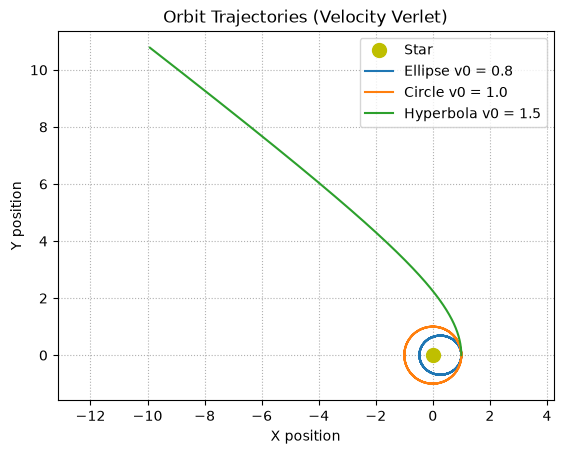

In [14]:
r = np.array([1.0, 0.0])
v = np.array([0.0, 1.0])
a = accel(r)

dt = 0.001
rs_10 = [r.copy()]
for _ in range(20000):
    r, v, a = verlet_step(r, v, a, dt, accel)
    rs_10.append(r.copy())
rs_10 = np.array(rs_10)

r = np.array([1.0, 0.0])
v = np.array([0.0, 0.8])   # less than circular speed (=1.0) -> ellipse
a = accel(r)

dt = 0.001
rs_08 = [r.copy()]
for _ in range(20000):
    r, v, a = verlet_step(r, v, a, dt, accel)
    rs_08.append(r.copy())
rs_08 = np.array(rs_08)

r = np.array([1.0, 0.0])
v = np.array([0.0, 1.5])   # less than circular speed (=1.0) -> ellipse
a = accel(r)

dt = 0.001
rs_15 = [r.copy()]
for _ in range(20000):
    r, v, a = verlet_step(r, v, a, dt, accel)
    rs_15.append(r.copy())
rs_15 = np.array(rs_15)

plt.plot(0, 0, "yo", markersize=10, label="Star")

plt.plot(rs_08[:,0], rs_08[:,1], label="Ellipse v0 = 0.8")
plt.plot(rs_10[:,0], rs_10[:,1], label="Circle v0 = 1.0")
plt.plot(rs_15[:,0], rs_15[:,1], label="Hyperbola v0 = 1.5")

plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)
plt.axis('equal')
plt.grid(True, linestyle=':')
plt.legend()
plt.xlabel('X position')
plt.ylabel('Y position')
plt.title('Orbit Trajectories (Velocity Verlet)')

plt.show()

In [15]:
def energy(r, v, G=1.0, M=1.0, m=1.0):
    ke = 0.5 * m * np.dot(v, v)
    pe = -G * M * m / np.linalg.norm(r)
    return ke + pe

def ang_momentum(r, v, m=1.0):
    # 2D cross product r x v is a scalar
    return m * (r[0] * v[1] - r[1] * v[0])

In [20]:

def verlet_step(r, v, dt, accel_func):
    """One Velocity Verlet step. accel_func(r) returns acceleration at position r."""
    r_new = r + v * dt + 0.5 * a * dt**2
    a_new = accel_func(r_new)
    v_new = v + 0.5 * (a + a_new) * dt
    return r_new, v_new